# Temporal Change Detection and Sand Area Analysis

**Course:** ARTI 403 — Image Processing

This notebook compares refined sand masks across 25 locations
from 2019–2026.

**Input:** Spectral–texture segmentation masks with morphological refinement.

**Outputs:** Annual sand-area statistics, temporal change maps,
comparison tables, and figures.

Changes represent differences in classified sand coverage.
They are not independently validated measurements of dune movement.

In [1]:
from pathlib import Path
import subprocess
import os

project = Path("/content/Sand-Dune-Segmentation")

if not project.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1", "--branch", "main",
            "https://github.com/BatoolAshour/Sand-Dune-Segmentation.git",
            str(project)
        ],
        check=True
    )

os.chdir(project)

print("Project folder:", Path.cwd())
print(
    "Repository version:",
    subprocess.check_output(
        ["git", "rev-parse", "HEAD"], text=True
    ).strip()
)

Project folder: /content/Sand-Dune-Segmentation
Repository version: c1fc3eff3f67373ca8ddef406359269c36c4e3df


In [2]:
%pip -q install rasterio pandas numpy matplotlib

In [3]:
import json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

mask_folder = project / "Texture Morphology Results" / "masks"
output = project / "Temporal Change Results"

for folder in ["tables", "change_maps", "figures"]:
    (output / folder).mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(project / "RawDataset" / "metadata.csv")

print("Input folder exists:", mask_folder.exists())
print("Metadata rows:", len(metadata))
print("Output folder:", output)

Input folder exists: True
Metadata rows: 200
Output folder: /content/Sand-Dune-Segmentation/Temporal Change Results


In [4]:
observations = {}
annual_rows = []

files = sorted(mask_folder.glob("*/*_refined.tif"))
assert len(files) == 200, f"Expected 200 masks, found {len(files)}"

for path in files:
    # Example filename: L1_Abqaiq_N_2019_refined.tif
    name, year_text = path.stem.removesuffix("_refined").rsplit("_", 1)
    year = int(year_text)
    site = name.split("_")[0]
    key = (site, year)

    assert key not in observations, f"Duplicate observation: {key}"

    with rasterio.open(path) as src:
        mask = src.read(1)
        readable = src.read_masks(1) > 0
        profile = src.profile.copy()
        transform = src.transform
        crs = src.crs

    assert set(np.unique(mask)).issubset({0, 1, 255}), \
        f"Unexpected mask values: {path.name}"
    assert mask.shape == (400, 400), \
        f"Unexpected dimensions: {path.name}"
    assert crs is not None and crs.to_epsg() == 32639, \
        f"Unexpected CRS: {path.name}"

    # Determinant of the affine transform gives pixel area in square metres.
    pixel_km2 = abs(
        transform.a * transform.e - transform.b * transform.d
    ) / 1_000_000

    assert np.isclose(pixel_km2, 0.0001), \
        f"Unexpected pixel area: {path.name}"

    valid = readable & np.isin(mask, [0, 1])
    sand = (mask == 1) & valid

    valid_count = int(valid.sum())
    sand_count = int(sand.sum())

    assert valid_count > 0, f"No valid pixels: {path.name}"

    observations[key] = {
        "mask": mask,
        "valid": valid,
        "profile": profile,
        "transform": transform,
        "crs": crs,
        "pixel_km2": pixel_km2,
        "name": name
    }

    annual_rows.append({
        "location_id": site,
        "location": name,
        "year": year,
        "valid_pixels": valid_count,
        "sand_pixels": sand_count,
        "valid_area_km2": valid_count * pixel_km2,
        "sand_area_km2": sand_count * pixel_km2,
        "sand_coverage_pct": 100 * sand_count / valid_count
    })

sites = sorted(
    {site for site, year in observations},
    key=lambda s: int(s[1:])
)
years = list(range(2019, 2027))

assert len(sites) == 25

for site in sites:
    assert {y for s, y in observations if s == site} == set(years), \
        f"Missing years for {site}"

    reference = observations[(site, 2019)]

    for year in years:
        current = observations[(site, year)]
        assert current["crs"] == reference["crs"]
        assert current["transform"] == reference["transform"], \
            f"Grid mismatch: {site}, {year}"

annual = pd.DataFrame(annual_rows)

site_dates = metadata[
    ["location_id", "year", "site_row", "acquisition_date"]
].copy()

assert not site_dates.duplicated(["location_id", "year"]).any()

annual = annual.merge(
    site_dates,
    on=["location_id", "year"],
    how="left",
    validate="one_to_one"
)

assert annual["acquisition_date"].notna().all()

annual.to_csv(output / "tables" / "annual_sand_area.csv", index=False)

print("Validated:", len(observations), "masks")
print("Locations:", len(sites))
print("Years:", years)
display(annual[annual.location_id == "L1"].sort_values("year"))

Validated: 200 masks
Locations: 25
Years: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


,location_id,location,year,valid_pixels,sand_pixels,valid_area_km2,sand_area_km2,sand_coverage_pct,site_row,acquisition_date
10,L1,L1_Abqaiq_N,2019,160000,133274,16.0000,13.3274,83.296250,road,2019-03-04
35,L1,L1_Abqaiq_N,2020,160000,134189,16.0000,13.4189,83.868125,road,2020-03-03
60,L1,L1_Abqaiq_N,2021,160000,139251,16.0000,13.9251,87.031875,road,2021-03-08
85,L1,L1_Abqaiq_N,2022,160000,137990,16.0000,13.7990,86.243750,road,2022-03-03
110,L1,L1_Abqaiq_N,2023,160000,131003,16.0000,13.1003,81.876875,road,2023-03-03
135,L1,L1_Abqaiq_N,2024,160000,124655,16.0000,12.4655,77.909375,road,2024-02-26
160,L1,L1_Abqaiq_N,2025,159996,114105,15.9996,11.4105,71.317408,road,2025-03-02
185,L1,L1_Abqaiq_N,2026,160000,115072,16.0000,11.5072,71.920000,road,2026-03-07


In [5]:
existing = pd.read_csv(
    project / "Texture Morphology Results" / "summary.csv"
)

check = annual.merge(
    existing[["location", "year", "dune_area_km2"]],
    on=["location", "year"],
    validate="one_to_one"
)

assert len(check) == 200

check["difference_km2"] = (
    check["sand_area_km2"] - check["dune_area_km2"]
)

# The existing refinement summary rounds areas to three decimal places.
assert check["difference_km2"].abs().max() <= 0.00051, \
    "Areas do not agree with the existing summary; investigate."

print("Area calculations agree with the existing rounded refinement summary.")

Area calculations agree with the existing rounded refinement summary.


In [6]:
# Change-map codes:
# 0 = persistent non-sand
# 1 = persistent sand
# 2 = sand gain
# 3 = sand loss
# 255 = excluded / invalid

pairs = [(year, year + 1) for year in range(2019, 2026)]
pairs += [(2019, 2026)]

change_rows = []

date_lookup = annual.set_index(
    ["location_id", "year"]
)["acquisition_date"].to_dict()

group_lookup = annual.set_index(
    ["location_id", "year"]
)["site_row"].to_dict()

for site in sites:
    for first_year, last_year in pairs:
        first = observations[(site, first_year)]
        last = observations[(site, last_year)]

        common_valid = first["valid"] & last["valid"]
        common_count = int(common_valid.sum())
        assert common_count > 0

        before = first["mask"] == 1
        after = last["mask"] == 1

        persistent_non_sand = common_valid & ~before & ~after
        persistent_sand = common_valid & before & after
        gain = common_valid & ~before & after
        loss = common_valid & before & ~after

        change_map = np.full(before.shape, 255, dtype=np.uint8)
        change_map[persistent_non_sand] = 0
        change_map[persistent_sand] = 1
        change_map[gain] = 2
        change_map[loss] = 3

        pixel_area = first["pixel_km2"]

        before_count = int((before & common_valid).sum())
        after_count = int((after & common_valid).sum())
        gain_count = int(gain.sum())
        loss_count = int(loss.sum())

        # Check that the classifications and accounting are consistent.
        assert (
            persistent_non_sand.sum() + persistent_sand.sum()
            + gain_count + loss_count
        ) == common_count

        assert after_count - before_count == gain_count - loss_count

        comparison = (
            "full_period" if (first_year, last_year) == (2019, 2026)
            else "consecutive"
        )

        map_name = f"{site}_{first_year}_{last_year}_change.tif"
        profile = first["profile"].copy()

        # Remove inherited TIFF block settings.
        profile.pop("blockxsize", None)
        profile.pop("blockysize", None)

        profile.update(
            driver="GTiff",
            count=1,
            dtype="uint8",
            nodata=255,
            compress="deflate",
            tiled=False
        )

        with rasterio.open(
            output / "change_maps" / map_name, "w", **profile
        ) as dst:
            dst.write(change_map, 1)
            dst.update_tags(
                classes="0=persistent_non_sand;1=persistent_sand;"
                        "2=sand_gain;3=sand_loss;255=invalid",
                first_year=str(first_year),
                last_year=str(last_year)
            )

        change_rows.append({
            "location_id": site,
            "site_row": group_lookup[(site, first_year)],
            "comparison": comparison,
            "first_year": first_year,
            "last_year": last_year,
            "first_date": date_lookup[(site, first_year)],
            "last_date": date_lookup[(site, last_year)],
            "common_valid_area_km2": common_count * pixel_area,
            "sand_before_km2": before_count * pixel_area,
            "sand_after_km2": after_count * pixel_area,
            "gain_km2": gain_count * pixel_area,
            "loss_km2": loss_count * pixel_area,
            "persistent_sand_km2": int(persistent_sand.sum()) * pixel_area,
            "persistent_non_sand_km2":
                int(persistent_non_sand.sum()) * pixel_area,
            "net_change_km2": (gain_count - loss_count) * pixel_area,
            "total_changed_km2": (gain_count + loss_count) * pixel_area,
            "changed_area_pct":
                100 * (gain_count + loss_count) / common_count,
            "relative_sand_change_pct":
                100 * (after_count - before_count) / before_count
                if before_count else np.nan,
            "map_filename": map_name
        })

changes = pd.DataFrame(change_rows)

assert len(changes) == 200

changes.to_csv(
    output / "tables" / "temporal_change_statistics.csv",
    index=False
)

full_period = changes[
    changes.comparison == "full_period"
].copy()

full_period.to_csv(
    output / "tables" / "change_2019_2026.csv",
    index=False
)

print("Saved:", len(changes), "change maps and comparison records")
display(
    full_period[
        ["location_id", "gain_km2", "loss_km2",
         "net_change_km2", "total_changed_km2"]
    ]
)

Saved: 200 change maps and comparison records


,location_id,gain_km2,loss_km2,net_change_km2,total_changed_km2
7,L1,0.3665,2.1867,-1.8202,2.5532
15,L2,0.5445,4.1185,-3.5740,4.6630
23,L3,0.1490,2.8474,-2.6984,2.9964
31,L4,0.0249,1.6471,-1.6222,1.6720
39,L5,0.3146,1.7041,-1.3895,2.0187
47,L6,0.0402,1.3731,-1.3329,1.4133
55,L7,0.1559,6.4060,-6.2501,6.5619
63,L8,0.0172,0.3155,-0.2983,0.3327
71,L9,0.0514,0.0428,0.0086,0.0942
79,L10,0.7352,0.6688,0.0664,1.4040


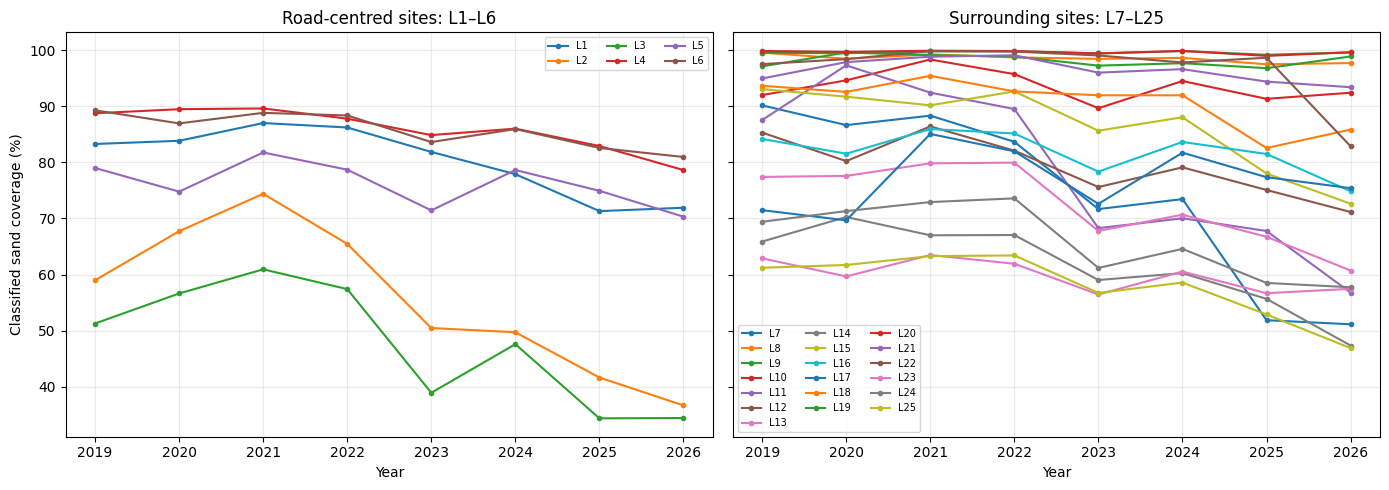

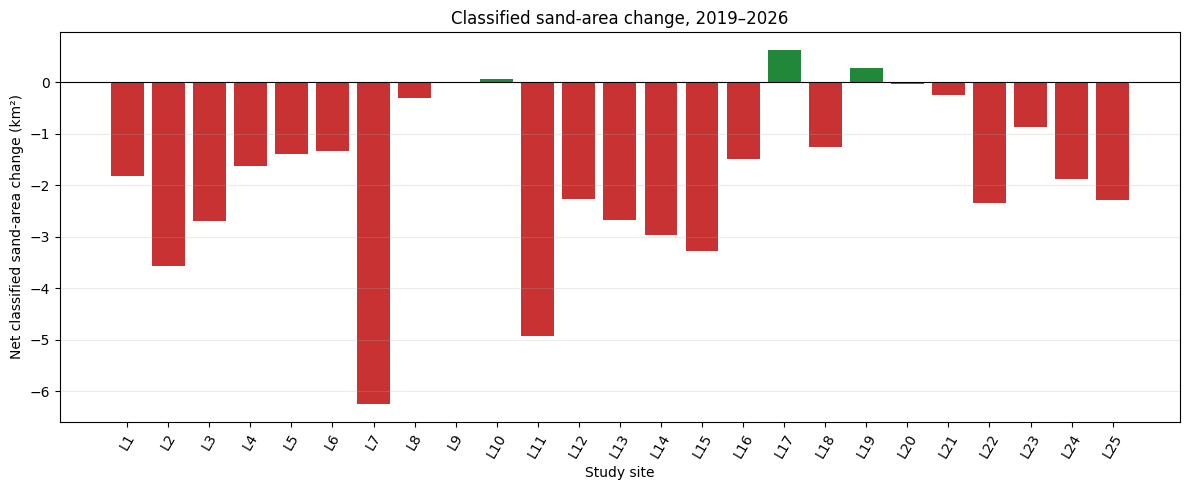

In [7]:
# Annual coverage trends, separating highway-centred sites.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, road_sites, title in [
    (axes[0], True, "Road-centred sites: L1–L6"),
    (axes[1], False, "Surrounding sites: L7–L25")
]:
    subset = annual[
        (annual["site_row"] == "road") == road_sites
    ]

    for site in sites:
        data = subset[
            subset.location_id == site
        ].sort_values("year")

        if not data.empty:
            ax.plot(
                data.year, data.sand_coverage_pct,
                marker="o", markersize=3, label=site
            )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_xticks(years)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, ncol=3)

axes[0].set_ylabel("Classified sand coverage (%)")
fig.tight_layout()
fig.savefig(
    output / "figures" / "annual_coverage_trends.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Full-period net change.
plot_data = full_period.set_index("location_id").loc[sites]

colours = [
    "#218739" if value >= 0 else "#c83232"
    for value in plot_data.net_change_km2
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(sites, plot_data.net_change_km2, color=colours)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Study site")
ax.set_ylabel("Net classified sand-area change (km²)")
ax.set_title("Classified sand-area change, 2019–2026")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    output / "figures" / "net_change_2019_2026.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

In [8]:
def inspect_rgb_change(site, first_year=2019, last_year=2026):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, year in zip(axes[:2], [first_year, last_year]):
        observation = observations[(site, year)]

        image_path = (
            project / "Processed Dataset" / "geotiff" / str(year)
            / f"{observation['name']}_{year}_processed.tif"
        )

        with rasterio.open(image_path) as src:
            rgb = np.moveaxis(src.read([3, 2, 1]), 0, -1)

        # Same display scale for both dates.
        rgb = np.clip(rgb / 0.6, 0, 1)
        rgb = np.nan_to_num(rgb)
        rgb[~observation["valid"]] = [0.33, 0.33, 0.33]

        ax.imshow(rgb, interpolation="nearest")
        ax.set_title(f"{site}: {date_lookup[(site, year)]}")
        ax.axis("off")

    change_path = (
        output / "change_maps"
        / f"{site}_{first_year}_{last_year}_change.tif"
    )

    with rasterio.open(change_path) as src:
        change = src.read(1)

    cmap = ListedColormap(
        ["#eeeeee", "#f2d77b", "#218739", "#c83232"]
    )
    cmap.set_bad("#555555")

    axes[2].imshow(
        np.ma.masked_where(change == 255, change),
        cmap=cmap,
        norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N),
        interpolation="nearest"
    )
    axes[2].set_title("Classified sand-cover change")
    axes[2].axis("off")

    legend = [
        Patch(color="#eeeeee", label="Persistent non-sand"),
        Patch(color="#f2d77b", label="Persistent sand"),
        Patch(color="#218739", label="Sand gain"),
        Patch(color="#c83232", label="Sand loss"),
        Patch(color="#555555", label="Excluded")
    ]

    fig.legend(
        handles=legend, loc="lower center", ncol=5,
        title="Change-map classes — right panel", fontsize=9
    )
    fig.tight_layout(rect=[0, 0.13, 1, 1])

    fig.savefig(
        output / "figures"
        / f"{site}_{first_year}_{last_year}_RGB_change.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

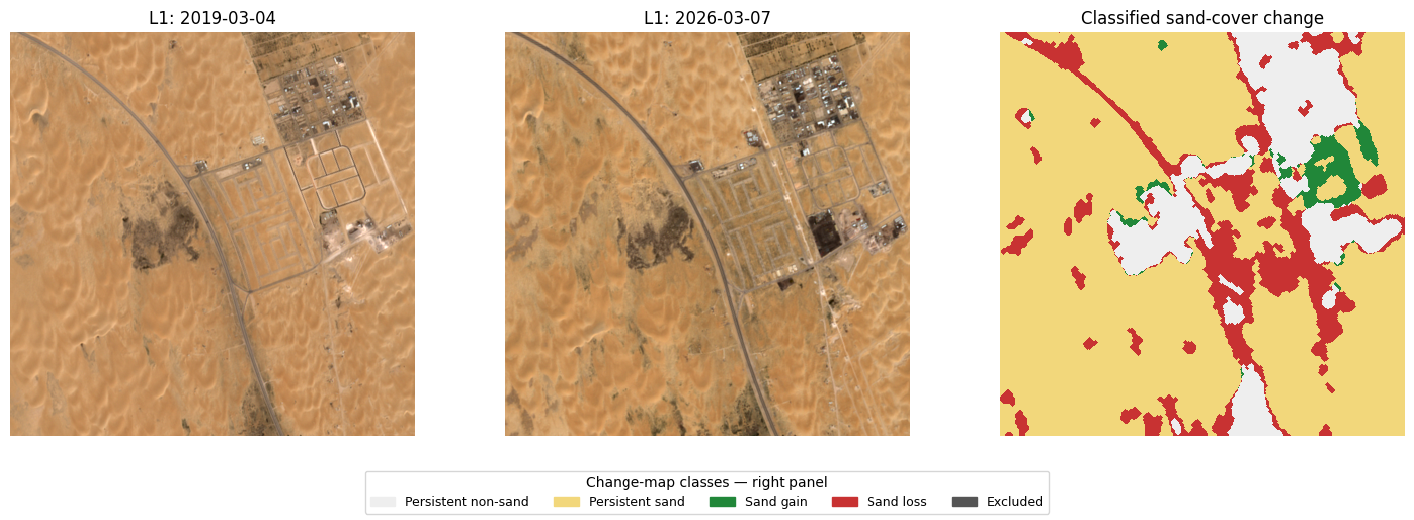

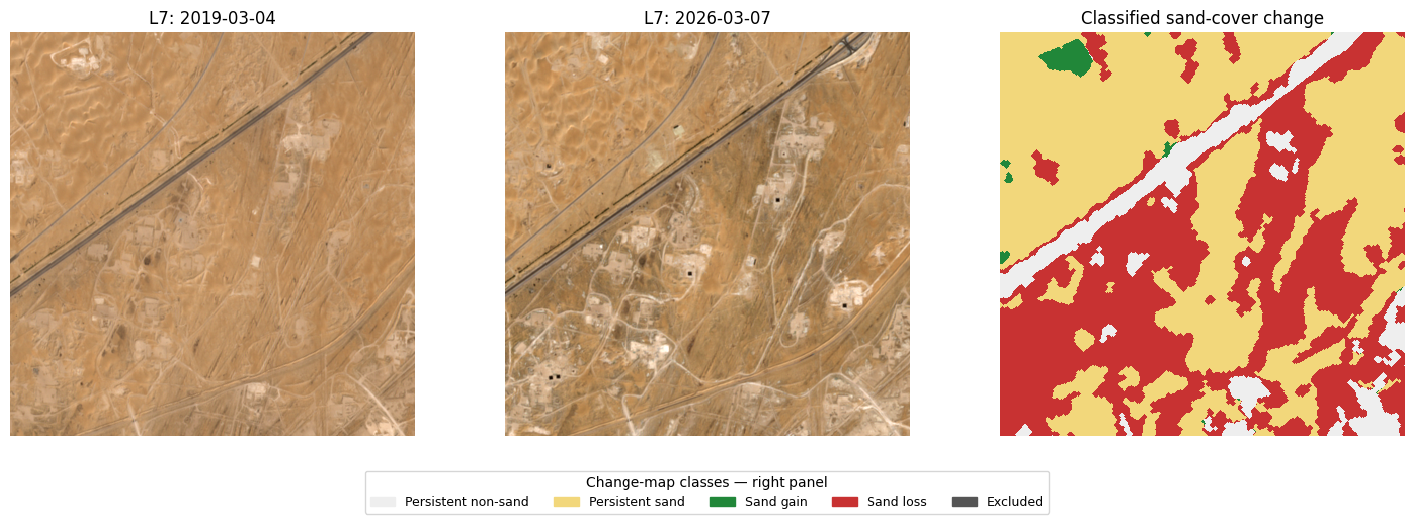

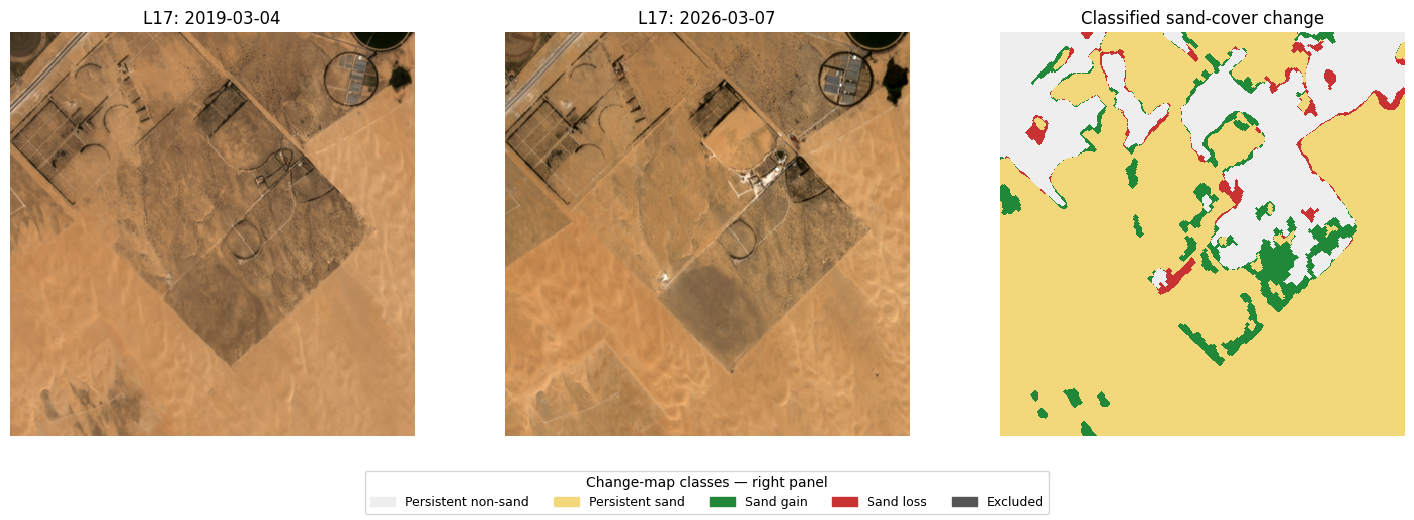

In [9]:
# Representative examples:
# L1: road-centred site
# L7: largest classified net decrease
# L17: largest classified net increase

for site in ["L1", "L7", "L17"]:
    inspect_rgb_change(site)

In [10]:
# Record the inputs and repository version used.
provenance = {
    "repository_commit": subprocess.check_output(
        ["git", "rev-parse", "HEAD"], text=True
    ).strip(),
    "input_masks": str(mask_folder.relative_to(project)),
    "mask_values": {
        "0": "non-sand",
        "1": "sand",
        "255": "invalid"
    },
    "observations": len(annual),
    "comparisons": len(changes),
    "interpretation": (
        "Changes in classified sand coverage; "
        "not independently validated dune movement."
    ),
    "status": "Pending team confirmation and segmentation evaluation."
}

(output / "analysis_provenance.json").write_text(
    json.dumps(provenance, indent=2)
)

# Create and download a ZIP containing all generated results.
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/Temporal_Change_Results",
    "zip",
    root_dir=output
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>